# SBSZ01: checking every ZARONIA coupon from first principles

This notebook looks at one bond, Standard Bank's SBSZ01 floating-rate note, which pays compounded ZARONIA plus 102 basis points. It asks two questions.

1. **Can the coupons the issuer has published be rebuilt from the SARB's daily fixings and the terms of the pricing supplement alone?** Section 4 works through the payment of 26 May 2026 line by line, and section 4b runs the same engine over every coupon whose fixings have been published and sets each result beside the issuer's SENS notice, both the rate and the rand amount.
2. **How much does the price move when investors want a wider spread?** Sections 6 to 8 value the note just after the May 2026 coupon at three discount margins, and solve the other way, from a price back to the spread it implies.

**Code and inputs are kept apart.** The notebook holds only the method. Everything it is told about the world lives in plain files next to it, each with its source:

| File | What it holds |
| --- | --- |
| `inputs/sbsz01_terms.json` | The note's terms, each with the clause of the pricing supplement it comes from |
| `inputs/sens_notices.csv` | What the issuer published for each payment: the rate as printed and the rand amount |
| `inputs/nominal_history.csv` | The amount in issue over time, from the issuer's announcements |
| `inputs/repo_rate_changes.csv` | The SARB's repo rate decisions, used only for the history chart |
| `inputs/declared_holidays.csv` | One-off public holidays such as election days; the regular ones are worked out by rule |
| `data/sarb_MMRD855A_cache.json` | The SARB API's reply, saved byte for byte and checked against its SHA-256. Used by default, so every run reproduces the summary; tick `REFRESH_FROM_SARB` to ask the SARB live instead |

To check another ZARONIA note, the files change and the notebook does not. When the next SENS notice is out, add a row to `sens_notices.csv`; to include newer coupons, move `DATA_AS_OF` forward or clear it.

**Running it.** In Google Colab, choose Runtime → Run all: the first cell fetches `inputs/` and `data/` from the GitHub repository named in `INPUTS_BASE_URL`. Run locally from a copy of the repository, it uses the files next to it. It needs pandas and matplotlib, which Colab already has. By default it uses the saved SARB reply, so it reproduces the summary exactly, and a regression check near the end confirms the headline results; tick `REFRESH_FROM_SARB` to use live data, which can include later revisions. When it finishes, download **SBSZ01_results.zip** from the Files sidebar.

Two cautions. The prices are scenarios from a simple model with stated assumptions, not fair values. And the notices do not state the nominal in issue, so the rand comparisons take it from the issuer's tap announcement of 17 September 2025. Where the rand amount then ties to the cent, it confirms the nominal as well as the rate.

**Sources:** the [pricing supplement](https://clientportal.jse.co.za/Content/JSEPricingSupplementsItems/2025/SBSZ01%20PricingSupplement2605.pdf) dated 21 May 2025; the issuer's SENS interest notices; the [SENS tap notice of 17 September 2025](https://senspdf.jse.co.za/documents/SENS_20250917_S510660.pdf); the [programme memorandum](https://www.standardbank.com/static_file/Investor%20Relations/Documents/Debt-investors/SBSA-Domestic-Medium-term-programme/SBSA-Programme-Memorandum_2024.pdf) dated 19 December 2024 (condition 7.2(h), printed page 49); the SARB's [ZARONIA page](https://www.resbank.co.za/en/home/what-we-do/financial-markets/south-african-overnight-index-average), web API and MPC statements; the government's list of [public holidays](https://www.gov.za/about-sa/public-holidays). Each input file names the source of every row.

## 1. Set up the case study

We start by loading the libraries and reading the inputs. The cell finds the folder holding `inputs/` and `data/`, reads the note's terms from `inputs/sbsz01_terms.json` and prints them with the clause each comes from, and reads the published notices, the nominal history, the repo rate decisions and any declared holidays.

A few things at the top are choices made for this case study rather than facts about the note: which payment to walk through in section 4 (26 May 2026), and which discount margin scenarios to run. In Colab they show as a small form.

The cell also checks that the terms describe a note this code knows how to calculate: Modified Following, a lookback without an observation shift, and the previous-published-rate fallback. A note with different conventions stops the run, rather than being calculated the wrong way.

The rates in the coupon calculation are held as Python `Decimal` numbers. That may look fussy, but the contract rounds to four decimal places, and ordinary floating-point numbers can occasionally land on the wrong side of a rounding boundary.

In [16]:
from datetime import date, timedelta
from decimal import Decimal, ROUND_HALF_UP
from hashlib import sha256
from io import BytesIO
import json
import urllib.request
from zipfile import ZipFile, ZIP_DEFLATED
from math import prod
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

# Two short names that are used all the way through: D for exact decimal numbers,
# and DAY for a step of one calendar day.
D = Decimal
DAY = timedelta(days=1)

# ----------------------------------------------------------------------------
# Choices made for this case study, rather than facts about the note. In Colab
# they show as a small form you can edit.
# ----------------------------------------------------------------------------
WALKTHROUGH_PAYMENT_DATE = "2026-05-26"  # @param {type:"string"}
REFRESH_FROM_SARB = False                # @param {type:"boolean"}
DATA_AS_OF = "2026-11-13"                # @param {type:"string"}
# By default the notebook uses the SARB reply saved in data/, checked against its
# checksum, so every run reproduces the summary exactly. Tick REFRESH_FROM_SARB to
# ask the SARB live instead; any fixing it has revised since is reported.
# DATA_AS_OF is the last fixing date used; clear it to use everything up to today.
SCENARIO_WIDENINGS_BP = [0, 25, 50]      # discount margin scenarios, over the contractual margin
INPUTS_BASE_URL = "https://raw.githubusercontent.com/Ikaelelo/sbsz01-zaronia-coupon-check/main"  # @param {type:"string"}
# INPUTS_BASE_URL is where the notebook fetches inputs/ and data/ when it cannot
# find them next to itself, as in a fresh Colab session opened from GitHub. Run
# locally, the files beside the notebook are used and this address is ignored.

INPUT_FILES = [
    "inputs/sbsz01_terms.json", "inputs/sens_notices.csv", "inputs/nominal_history.csv",
    "inputs/repo_rate_changes.csv", "inputs/declared_holidays.csv",
    "data/sarb_MMRD855A_cache.json", "data/sarb_MMRD855A_cache.meta.json",
]


def find_project_folder():
    """Find the folder holding inputs/ and data/, fetching or unpacking it if needed.

    Run locally, the folder is the one the notebook sits in. In a fresh Colab
    session nothing is there yet, so the notebook downloads the files from
    INPUTS_BASE_URL if one is given, or asks you to upload the case-study zip.
    """
    for folder in (Path.cwd(), Path.cwd() / "SBSZ01_case_study"):
        if (folder / INPUT_FILES[0]).exists():
            return folder
    folder = Path.cwd() / "SBSZ01_case_study"
    if INPUTS_BASE_URL:
        for name in INPUT_FILES:
            (folder / name).parent.mkdir(parents=True, exist_ok=True)
            with urllib.request.urlopen(INPUTS_BASE_URL.rstrip("/") + "/" + name, timeout=20) as reply:
                (folder / name).write_bytes(reply.read())
        return folder
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Run the notebook from the SBSZ01_case_study folder, "
                                "next to its inputs/ and data/ folders.") from None
    print("Upload SBSZ01_case_study.zip, the zip this notebook came in.")
    for name, content in files.upload().items():
        with ZipFile(BytesIO(content)) as archive:
            archive.extractall(Path.cwd())
    if not (folder / INPUT_FILES[0]).exists():
        raise FileNotFoundError("The upload did not contain SBSZ01_case_study/inputs/.")
    return folder


PROJECT = find_project_folder()

# ----------------------------------------------------------------------------
# The terms of the note, read from inputs/sbsz01_terms.json. Each one carries the
# clause of the pricing supplement it comes from, and is printed below.
# ----------------------------------------------------------------------------
TERMS_FILE = json.loads((PROJECT / "inputs/sbsz01_terms.json").read_text(encoding="utf-8"))
term = {name: item["value"] for name, item in TERMS_FILE["terms"].items()}

CALCULATION_AMOUNT = D(term["calculation_amount"])
INTEREST_COMMENCEMENT = date.fromisoformat(term["interest_commencement_date"])
MATURITY = date.fromisoformat(term["maturity_date"])
PAYMENT_DAY, PAYMENT_MONTHS = term["payment_day_of_month"], term["payment_months"]
DAYS_IN_YEAR = term["day_count_denominator"]
MARGIN_PCT = D(term["margin_pct"])
LOOKBACK = term["lookback_business_days"]
BENCHMARK_QUANTUM = D(1).scaleb(-term["benchmark_rounding_decimals"])   # 0.0001
SARB_SERIES = TERMS_FILE["reference_rate"]["sarb_series"]
# The notebook implements one convention of each kind. If the terms file ever
# describes a different note, stop rather than calculate it the wrong way.
if (term["business_day_convention"], term["observation_shift"], term["missing_fixing_rule"]) != (
        "modified_following", False, "previous_published"):
    raise NotImplementedError("These terms use a convention this notebook does not implement.")

# ----------------------------------------------------------------------------
# What the issuer published, and the other observed facts the checks use.
# ----------------------------------------------------------------------------
notices = pd.read_csv(PROJECT / "inputs/sens_notices.csv", dtype=str, keep_default_na=False)
PUBLISHED_NOTICES = {
    date.fromisoformat(row.payment_date): {
        "rate": row.rate_as_printed_pct or None, "cash": row.interest_rand or None,
        "source": row.source or None, "note": row.note or None,
    }
    for row in notices.itertuples(index=False)
}
nominal_history = pd.read_csv(PROJECT / "inputs/nominal_history.csv", dtype=str)
NOMINALS = sorted((date.fromisoformat(r.in_issue_from), D(r.nominal_rand))
                  for r in nominal_history.itertuples(index=False))
repo_table = pd.read_csv(PROJECT / "inputs/repo_rate_changes.csv", dtype=str)
REPO_CHANGES = sorted((date.fromisoformat(r.effective_date), float(r.repo_rate_pct))
                      for r in repo_table.itertuples(index=False))
declared = pd.read_csv(PROJECT / "inputs/declared_holidays.csv", dtype=str)
DECLARED_HOLIDAYS = {date.fromisoformat(r.date): r.name for r in declared.itertuples(index=False)}

WALKTHROUGH_PAYMENT = date.fromisoformat(WALKTHROUGH_PAYMENT_DATE)


def nominal_on(day):
    """The nominal amount in issue on a given day, from inputs/nominal_history.csv."""
    return [amount for since, amount in NOMINALS if since <= day][-1]


# Everything the notebook produces is written to this folder, which is zipped
# at the end so that it can be downloaded in one go.
OUTPUT_DIR = Path("SBSZ01_results")
RESULTS_ZIP = Path("SBSZ01_results.zip")
# Start from an empty results folder, so nothing from an earlier run is carried over.
import shutil
shutil.rmtree(OUTPUT_DIR, ignore_errors=True)
RESULTS_ZIP.unlink(missing_ok=True)
OUTPUT_DIR.mkdir()


def save_and_show(fig, filename):
    """Save a chart into the results folder and show it underneath the cell."""
    fig.savefig(OUTPUT_DIR / filename, dpi=150)
    # The copy shown on screen is drawn at a slightly lower resolution than the
    # saved file. Closing the figure afterwards stops Colab from drawing it twice.
    with BytesIO() as chart:
        fig.savefig(chart, format="png", dpi=130)
        display(Image(data=chart.getvalue()))
    plt.close(fig)


print(f"Inputs read from the {PROJECT.name} folder")
display(pd.DataFrame(
    [(name, item["value"], item["source"]) for name, item in TERMS_FILE["terms"].items()],
    columns=["Term", "Value", "Pricing supplement"]).set_index("Term"))

Inputs read from the SBSZ01_case_study folder


,Value,Pricing supplement
Term,,
calculation_amount,1000000,"item 15, page 1"
interest_commencement_date,2025-05-26,"pricing supplement, page 2"
maturity_date,2028-05-26,"item 18, page 2"
business_day_convention,modified_following,"item 21, page 2"
payment_day_of_month,26,"item 29, page 2"
payment_months,"[2, 5, 8, 11]","item 29, page 2"
day_count_denominator,365,"item 29(f), page 3 (Actual/365)"
margin_pct,1.02,"item 31, page 3"
lookback_business_days,5,"items 33(f)-(h), page 3"


## 2. Build the calendar and the payment schedule

Before we can touch any rates, we need to know which days matter. The note earns interest for every calendar day in a period, but ZARONIA is only published on Johannesburg business days. So the contract works through the period one business day at a time, and for each one we need to know two things: how many calendar days it has to cover before the next business day arrives, and which fixing it should use.

The answer to the first is usually one day. A Friday covers three, because it also carries the weekend, and the day before a public holiday covers more. The answer to the second is the fixing from five business days earlier. This is the lookback, and it is there so that the coupon is known a few days before it has to be paid.

**Public holidays are worked out, not listed.** The Public Holidays Act fixes ten dates; Good Friday and Family Day follow Easter, which the cell calculates; and a holiday on a Sunday moves the day off to Monday. Only one-off holidays, such as election days, are read from `inputs/declared_holidays.csv`, because no rule can predict them. Section 3 cross-checks this calendar against the SARB's data.

One detail is easy to get wrong. The number of days a rate is applied for depends on the accrual date, and has nothing to do with the date on which the rate was observed.

Payment dates come from the terms file: the 26th of each payment month from the first after interest commencement to maturity. A date that falls on a weekend or a holiday is moved using the Modified Following rule: forward to the next business day, unless that would take us into the following month, in which case back to the last business day before it. The cell ends with checks that hold for every period: the day weights add up to the period's length, and no fixing is used twice.

In [17]:
def easter_sunday(year):
    """Easter Sunday in the Gregorian calendar (the 'anonymous' algorithm, 1876)."""
    a = year % 19
    b, c = divmod(year, 100)
    d, e = divmod(b, 4)
    f = (b + 8) // 25
    g = (b - f + 1) // 3
    h = (19 * a + b - d - g + 15) % 30
    i, k = divmod(c, 4)
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    month, day = divmod(h + l - 7 * m + 114, 31)
    return date(year, month, day + 1)


# The Public Holidays Act lists ten holidays on fixed dates. Good Friday and Family
# Day follow Easter. When any of them falls on a Sunday, the Monday after it is a
# holiday too. One-off holidays, such as election days, are declared separately
# and are read from inputs/declared_holidays.csv.
FIXED_HOLIDAYS = {
    (1, 1): "New Year's Day", (3, 21): "Human Rights Day", (4, 27): "Freedom Day",
    (5, 1): "Workers' Day", (6, 16): "Youth Day", (8, 9): "National Women's Day",
    (9, 24): "Heritage Day", (12, 16): "Day of Reconciliation", (12, 25): "Christmas Day",
    (12, 26): "Day of Goodwill",
}


def public_holidays(years):
    """Every South African public holiday in the given years, as {date: name}."""
    found = {}
    for year in years:
        found.update({date(year, m, d): name for (m, d), name in FIXED_HOLIDAYS.items()})
        easter = easter_sunday(year)
        found[easter - 2 * DAY] = "Good Friday"
        found[easter + DAY] = "Family Day"
    for day, name in list(found.items()):
        if day.weekday() == 6:
            found.setdefault(day + DAY, f"{name} (Monday after)")
    found.update({day: name for day, name in DECLARED_HOLIDAYS.items() if day.year in years})
    return found


holidays = public_holidays(range(INTEREST_COMMENCEMENT.year - 1, MATURITY.year + 1))


def is_business_day(day):
    """A Johannesburg business day is a weekday that is not a public holiday."""
    return day.weekday() < 5 and day not in holidays


def move_business_days(day, count):
    """Step forwards by `count` business days, or backwards if `count` is negative."""
    step = DAY if count >= 0 else -DAY
    for _ in range(abs(count)):
        # Take one calendar day's step, then keep going until we land on a business day.
        day += step
        while not is_business_day(day):
            day += step
    return day


def modified_following(day):
    """Adjust a payment date that is not a business day, using Modified Following."""
    if is_business_day(day):
        return day
    following = move_business_days(day, 1)
    # Normally the payment rolls forward. If that would push it into the next month,
    # it rolls back to the last business day of its own month instead.
    return following if following.month == day.month else move_business_days(day, -1)


def accrual_schedule(start, end):
    """Build one row for every business day in an interest period.

    The period runs from `start` up to, but not including, `end`. Each row records
    the business day itself, the next business day, the date whose fixing applies
    (LOOKBACK business days earlier) and the number of calendar days the row covers.
    """
    rows = []
    # Coupon dates have already been adjusted, so the period starts on a business day.
    accrual_date = start
    while accrual_date < end:
        next_accrual = move_business_days(accrual_date, 1)
        rows.append((accrual_date, next_accrual,
                     move_business_days(accrual_date, -LOOKBACK),
                     (next_accrual - accrual_date).days))
        accrual_date = next_accrual
    return pd.DataFrame(rows, columns=[
        "accrual_date", "next_accrual_date_exclusive", "observation_date", "weight_days",
    ])


# Every payment date for the life of the note: the 26th of each payment month from
# the first after interest commencement to maturity, each moved to a business day.
scheduled_dates = [date(year, month, PAYMENT_DAY)
                   for year in range(INTEREST_COMMENCEMENT.year, MATURITY.year + 1)
                   for month in PAYMENT_MONTHS
                   if INTEREST_COMMENCEMENT < date(year, month, PAYMENT_DAY) <= MATURITY]
all_payment_dates = [modified_following(day) for day in scheduled_dates]
all_periods = list(zip([INTEREST_COMMENCEMENT] + all_payment_dates[:-1], all_payment_dates))

# Checks that hold for every period, whatever the dates: the weights add up to the
# calendar days, every business day uses a different fixing, and the periods join up.
for start, end in all_periods:
    period = accrual_schedule(start, end)
    assert period["weight_days"].sum() == (end - start).days
    assert period["observation_date"].is_unique
assert scheduled_dates[-1] == MATURITY and all_payment_dates[-1] == modified_following(MATURITY)
print(f"{len(all_periods)} interest periods from {INTEREST_COMMENCEMENT} to {MATURITY}; "
      f"{len(holidays)} public holidays in the calendar, "
      f"{len([d for d in DECLARED_HOLIDAYS if d in holidays])} of them declared one-offs.")

12 interest periods from 2025-05-26 to 2028-05-26; 67 public holidays in the calendar, 1 of them declared one-offs.


## 3. Download and validate daily ZARONIA

By default the notebook uses `data/sarb_MMRD855A_cache.json`: the SARB API's reply for series `MMRD855A`, downloaded on 16 November 2026 and saved byte for byte, with its SHA-256 recorded next to it and checked before use. That makes every run reproduce the summary exactly. Tick `REFRESH_FROM_SARB` in section 1 to ask the SARB live instead: the notebook then compares the live figures with the saved reply, reports any fixing the SARB has revised since, and uses the live figures, so the results can differ from the summary. Either way, only fixings up to `DATA_AS_OF` (13 November 2026) are used.

**Which coupons can be calculated** follows from the data: every coupon whose last fixing has been published by that date. With `DATA_AS_OF` cleared, the next coupon is included as soon as its fixings are out, without any change to the code.

**Days with no fixing.** Schedule 1, paragraph 2(a) of the pricing supplement says what to do when no ZARONIA is published for a business day: use the rate last published for an earlier business day. The notebook applies that rule wherever a fixing is missing, and reports every case as an exception to confirm. A gap in today's download shows only that no rate is there now, not that none was published by the contractual time on the day; the issuer's notice for that coupon would settle it, so those coupons are marked "fallback applied, unconfirmed". If there is no earlier fixing at all, paragraph 2(b) would apply, which the notebook does not implement, so it stops.

**Checking the calendar against the data.** A business day with no fixing that no coupon needs is printed too, because it often means the calendar is missing a holiday. That is how the local government elections holiday of Wednesday 4 November 2026 showed up: it is now in `inputs/declared_holidays.csv`. A row dated on a weekend or holiday, such as the series' row for Saturday 2 May 2026, is set aside and reported, because the lookback can never land on it.

In [18]:
# Ask for a little more history than the first coupon needs, so that the
# alternative lookbacks tested in section 4b have their fixings too.
FETCH_START = move_business_days(INTEREST_COMMENCEMENT, -(LOOKBACK + 10))
FETCH_END = min(date.fromisoformat(DATA_AS_OF) if DATA_AS_OF else date.today(), MATURITY)
SARB_URL = TERMS_FILE["reference_rate"]["api_url_template"].format(
    series=SARB_SERIES, start=FETCH_START, end=FETCH_END)
CACHE_FILE = PROJECT / "data/sarb_MMRD855A_cache.json"
CACHE_META = json.loads((PROJECT / "data/sarb_MMRD855A_cache.meta.json").read_text(encoding="utf-8"))


def fetch_bytes(url):
    """Download an address and return the raw reply, giving up after twenty seconds."""
    request = urllib.request.Request(url, headers={"Accept": "*/*", "User-Agent": "SBSZ01-case-study/1.0"})
    with urllib.request.urlopen(request, timeout=20) as response:
        return response.read()


def parse_sarb(body):
    """Read a reply from the SARB API into {date: rate}, checking every value.

    A duplicated date or an impossible value raises an error. Rows dated on a
    weekend or public holiday are set aside, because the lookback can never land
    on them; they are reported rather than silently dropped.
    """
    rows = json.loads(body, parse_float=D)
    if isinstance(rows, dict):
        keys = {key.lower(): value for key, value in rows.items()}
        rows = keys.get("observations", keys.get("data", keys.get("value")))
    if not isinstance(rows, list) or not all(isinstance(row, dict) for row in rows):
        raise ValueError("Unexpected SARB observations response.")
    rates, set_aside = {}, {}
    for row in ({k.lower(): v for k, v in r.items()} for r in rows):
        raw_date = row.get("period", row.get("date", row.get("observationdate")))
        raw_value = row.get("value", row.get("observationvalue"))
        if raw_date is None or raw_value is None:
            raise ValueError(f"Observation row without a date or value: {row}")
        day = date.fromisoformat(str(raw_date).strip()[:10].replace("/", "-"))
        rate = D(str(raw_value).strip())
        if day in rates or day in set_aside or not rate.is_finite() or not D("-10") < rate < D("30"):
            raise ValueError(f"Duplicate or invalid rate for {day}: {raw_value}")
        (rates if is_business_day(day) else set_aside)[day] = rate
    return rates, set_aside


def read_cache():
    """Read the saved SARB reply, after checking it is byte for byte what was saved."""
    body = CACHE_FILE.read_bytes()
    if sha256(body).hexdigest() != CACHE_META["sha256"]:
        raise ValueError("The cached SARB reply does not match its recorded checksum.")
    return body


cached_series, _ = parse_sarb(read_cache())


def use_cache(reason):
    """The saved SARB reply, after its checksum has been checked."""
    print(f"Using the saved SARB reply in data/, retrieved {CACHE_META['retrieved_at_utc'][:10]} ({reason}).")
    series, set_aside = parse_sarb(read_cache())
    provenance = {"source": "Saved SARB API reply", "source_url": CACHE_META["request_url"],
                  "retrieved_at_utc": CACHE_META["retrieved_at_utc"],
                  "response_sha256": CACHE_META["sha256"], "note": reason}
    return {d: r for d, r in series.items() if d <= FETCH_END}, set_aside, provenance


def ask_sarb():
    """Ask the SARB API live, and report any fixing it has revised since the saved reply."""
    print("Asking the SARB API ...")
    reply = fetch_bytes(SARB_URL)
    series, set_aside = parse_sarb(reply)
    series = {d: r for d, r in series.items() if d <= FETCH_END}
    (OUTPUT_DIR / "sarb_reply.json").write_bytes(reply)
    revisions = {str(day): [str(cached_series[day]), str(series.get(day))]
                 for day in cached_series
                 if FETCH_START <= day <= max(series) and series.get(day) != cached_series[day]}
    print("The SARB answered, with no revisions to the saved reply." if not revisions else
          f"The SARB now differs from the saved reply on {len(revisions)} date(s): {revisions}")
    provenance = {"source": "Direct SARB API", "source_url": SARB_URL,
                  "retrieved_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
                  "response_sha256": sha256(reply).hexdigest(),
                  "differences_from_saved_reply": revisions}
    return series, set_aside, provenance


if not REFRESH_FROM_SARB:
    series, set_aside, provenance = use_cache("REFRESH_FROM_SARB is off, so the results match the summary")
else:
    try:
        series, set_aside, provenance = ask_sarb()
    except (OSError, ValueError, KeyError, TypeError, ArithmeticError) as exc:
        print(f"The SARB could not be used ({type(exc).__name__}: {exc}).")
        series, set_aside, provenance = use_cache("the live request failed")
fixing_source = provenance["source"]
last_fixing_date = max(series)

# Which coupons can be calculated: those whose last fixing has been published.
paid_periods = [(s, e) for s, e in all_periods
                if accrual_schedule(s, e)["observation_date"].iloc[-1] <= last_fixing_date]

SUBSTITUTED = {}   # day with no fixing -> the earlier day whose fixing it uses


def fixing_for(day, record=True):
    """The fixing that applies to a business day, with the contract's fallback.

    Schedule 1, paragraph 2(a): if no ZARONIA is available for a business day, use
    the rate last published for an earlier business day. Every use is recorded in
    SUBSTITUTED and reported as an exception to confirm, because a gap in today's
    download does not prove the rate was unavailable at the contractual time.
    """
    if day in series:
        return series[day]
    if day > last_fixing_date:
        raise KeyError(f"No fixing for {day} has been published yet.")
    earlier = max((d for d in series if d < day), default=None)
    if earlier is None:
        # Paragraph 2(b), the repo rate plus an average spread, is not implemented.
        raise NotImplementedError(f"No earlier fixing for {day}: paragraph 2(b) would apply.")
    if record:
        SUBSTITUTED[day] = earlier
    return series[earlier]


# The fixings the coupons need, plus the first few fixings of the period after the
# walkthrough payment, which the pricing in section 6 uses.
valuation_period = next((s, e) for s, e in all_periods if s == WALKTHROUGH_PAYMENT)
valuation_observations = accrual_schedule(*valuation_period)["observation_date"].head(LOOKBACK).tolist()
all_required = sorted({o for s, e in paid_periods for o in accrual_schedule(s, e)["observation_date"]}
                      | set(valuation_observations))
fixings = {day: series[day] for day in all_required if day in series}
for day in all_required:
    fixing_for(day)   # applies and records the fallback where a fixing is missing

# Two cross-checks of the calendar against the data. A weekday with no fixing that
# no coupon needs, and a fixing on a day the calendar calls a holiday, both point to
# a calendar that may be out of date.
quiet_weekdays = [d for d in pd.bdate_range(FETCH_START, last_fixing_date).date
                  if is_business_day(d) and d not in series and d not in SUBSTITUTED]
print(f"Fixings used: {fixing_source} | data as of {FETCH_END} | {len(paid_periods)} coupons can be calculated | "
      f"{len(all_required)} fixing dates needed, {len(all_required) - len(SUBSTITUTED)} published and "
      f"{len(SUBSTITUTED)} filled by the fallback")
print("Exceptions to confirm: days with no fixing in this download, and the rate paragraph 2(a) uses instead.")
for day, earlier in sorted(SUBSTITUTED.items()):
    print(f"  {day}: uses the fixing for {earlier}, {series[earlier]}%. Confirm against the issuer's notice.")
for day in quiet_weekdays:
    print(f"  {day}: no fixing either, but no coupon calculated here needs it. Check the calendar.")
for day, rate in sorted(set_aside.items()):
    print(f"  {day} ({holidays.get(day, day.strftime('%A'))}): the series has a row, {rate}%, "
          "on a day that is not a business day. Ignored.")

fixing_table = pd.DataFrame({"reference_date": all_required,
                             "zaronia_pct": [fixing_for(d) for d in all_required],
                             "substituted_from": [SUBSTITUTED.get(d, "") for d in all_required],
                             "source": fixing_source,
                             "retrieved_at_utc": provenance["retrieved_at_utc"]})
fixing_table.to_csv(OUTPUT_DIR / "zaronia_fixings_used.csv", index=False)

Using the saved SARB reply in data/, retrieved 2026-11-16 (REFRESH_FROM_SARB is off, so the results match the summary).
Fixings used: Saved SARB API reply | data as of 2026-11-13 | 5 coupons can be calculated | 315 fixing dates needed, 312 published and 3 filled by the fallback
Exceptions to confirm: days with no fixing in this download, and the rate paragraph 2(a) uses instead.
  2026-01-29: uses the fixing for 2026-01-28, 6.6030%. Confirm against the issuer's notice.
  2026-07-15: uses the fixing for 2026-07-14, 6.8520%. Confirm against the issuer's notice.
  2026-07-16: uses the fixing for 2026-07-14, 6.8520%. Confirm against the issuer's notice.
  2026-05-02 (Saturday): the series has a row, 6.6170%, on a day that is not a business day. Ignored.


### Known-answer tests

The cells above are written to work for any dates. This one is different on purpose: it states answers that were worked out by hand or taken from published sources, and checks that the code reproduces them. Easter dates, a Sunday holiday moved to Monday, the election-day holiday, the shape of the May 2026 period, the Easter lookback, and Modified Following rolling both forwards and backwards. If any of them fails, the notebook stops here.

In [19]:
# Known answers, checked by hand or against published sources. Unlike the rest of
# the notebook, these dates are meant to be written out: a test states what the
# right answer is, and the code has to reproduce it.

# The Easter algorithm against published dates of Easter Sunday.
for year, easter in [(2000, date(2000, 4, 23)), (2019, date(2019, 4, 21)), (2025, date(2025, 4, 20)),
                     (2026, date(2026, 4, 5)), (2027, date(2027, 3, 28)), (2028, date(2028, 4, 16))]:
    assert easter_sunday(year) == easter, year
# Holidays that test each rule: a Sunday holiday moved to Monday, Easter, and the
# declared election day.
assert not is_business_day(date(2026, 8, 10))     # National Women's Day fell on a Sunday
assert not is_business_day(date(2026, 4, 3)) and not is_business_day(date(2026, 4, 6))
assert not is_business_day(date(2026, 11, 4))     # local government elections

# The May 2026 period: 89 calendar days, 59 business days, fixings from 19 February
# to 18 May, and the coupon fixed on 19 May, five business days before payment.
may = accrual_schedule(date(2026, 2, 26), date(2026, 5, 26))
assert len(may) == 59 and may["weight_days"].sum() == 89
assert (may["observation_date"].iloc[0], may["observation_date"].iloc[-1]) == (date(2026, 2, 19), date(2026, 5, 18))
assert move_business_days(date(2026, 5, 26), -LOOKBACK) == date(2026, 5, 19)

# Easter is the hardest test. Thursday 2 April covers five days (Good Friday, the
# weekend and Family Day) at the rate from Thursday 26 March, which was itself an
# ordinary one-day fixing: the weight comes from the accrual date, not the observation.
easter_row = may.loc[may["accrual_date"] == date(2026, 4, 2)].iloc[0]
assert (easter_row["observation_date"], easter_row["weight_days"]) == (date(2026, 3, 26), 5)
assert move_business_days(date(2026, 3, 26), 1) == date(2026, 3, 27)
# The first business day after Easter, Tuesday 7 April, looks back to Friday 27 March.
assert move_business_days(date(2026, 4, 7), -LOOKBACK) == date(2026, 3, 27)

# Modified Following both ways: 28 February 2027 is a Sunday, so the payment rolls
# back into February; 26 February 2028 is a Saturday, so it rolls forward to Monday.
assert modified_following(date(2027, 2, 28)) == date(2027, 2, 26)
assert modified_following(date(2028, 2, 26)) == date(2028, 2, 28)
print("Known-answer tests passed: Easter dates, holiday rules, the May 2026 period and both directions of Modified Following.")

Known-answer tests passed: Easter dates, holiday rules, the May 2026 period and both directions of Modified Following.


## 4. Walk through one coupon: 26 May 2026

The walkthrough period is the one ending on `WALKTHROUGH_PAYMENT_DATE`, set in section 1. The text in this section describes the May 2026 coupon; the code works for any coupon that has been fixed.

### What the calendar does to the calculation

The two charts below are drawn from the period's schedule, and they show the weekend and holiday effects at a glance.

The top chart shows how many calendar days each business day has to cover. Most cover one, and every Friday covers three. The highlighted bars carry a public holiday as well, and are labelled with it: in this period the days before Easter, Freedom Day and Workers' Day, which cover four or five days each.

The bottom chart shows how far back in the calendar each business day reaches for its fixing. Five business days is normally exactly a week. Around the public holidays it stretches to as much as eleven days, because the holidays do not count towards the five.

2026-02-26 inclusive to 2026-05-26 exclusive | 89 calendar days | 59 business days
Fixings from 2026-02-19 to 2026-05-18; coupon fixed on 2026-05-19


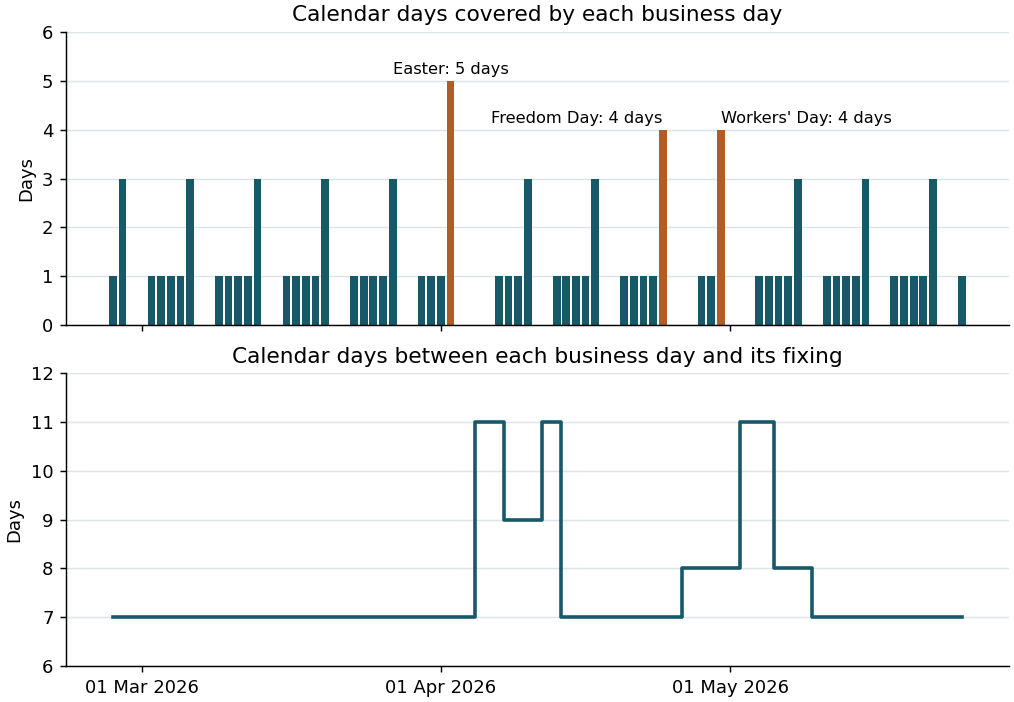

In [20]:
# The walkthrough period: the interest period that ends on WALKTHROUGH_PAYMENT_DATE.
start, end = next((s, e) for s, e in paid_periods if e == WALKTHROUGH_PAYMENT)
days = (end - start).days
audit = accrual_schedule(start, end)
required_dates = audit["observation_date"].tolist()
determination_date = move_business_days(end, -LOOKBACK)
print(f"{start} inclusive to {end} exclusive | {days} calendar days | {len(audit)} business days")
print(f"Fixings from {required_dates[0]} to {required_dates[-1]}; coupon fixed on {determination_date}")

# How many calendar days lie between each business day and the fixing it uses.
lookback_gap = [(accrual - observed).days
                for accrual, observed in zip(audit["accrual_date"], audit["observation_date"])]

# Two charts stacked on top of each other, sharing the same date axis.
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7.8, 5.4), sharex=True, layout="constrained")

# Top chart: the calendar days carried by each business day.
top.bar(audit["accrual_date"], audit["weight_days"], width=0.8, color="#175969")
# Business days that carry more than a normal weekend sit before a public holiday.
# Each is redrawn in a second colour and labelled with the holiday's name. When two
# labels would be close, the first sits to the left of its bar and the second to the right.
long_weekends = audit.loc[audit["weight_days"] > 3, ["accrual_date", "next_accrual_date_exclusive", "weight_days"]]
previous = None
for row in long_weekends.itertuples(index=False):
    names = [holidays[d] for d in pd.date_range(row.accrual_date, row.next_accrual_date_exclusive).date
             if d in holidays]
    reason = "Easter" if "Good Friday" in names else names[0]
    side = "center"
    if previous is not None and (row.accrual_date - previous[0]).days < 10:
        previous[1].set_horizontalalignment("right")
        side = "left"
    top.bar(row.accrual_date, row.weight_days, width=0.8, color="#b35d26")
    label = top.annotate(f"{reason}: {row.weight_days} days", (row.accrual_date, row.weight_days),
                         xytext=(0, 4), textcoords="offset points", ha=side, fontsize=9)
    previous = (row.accrual_date, label)
top.set(title="Calendar days covered by each business day", ylabel="Days",
        ylim=(0, audit["weight_days"].max() + 1))

# Bottom chart: the distance back to the fixing, drawn as steps because it only
# ever takes whole-day values.
bottom.plot(audit["accrual_date"], lookback_gap, drawstyle="steps-mid", color="#175969", linewidth=2)
bottom.set(title="Calendar days between each business day and its fixing", ylabel="Days",
           ylim=(min(lookback_gap) - 1, max(lookback_gap) + 1))
bottom.xaxis.set_major_locator(mdates.MonthLocator())
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))

for ax in (top, bottom):
    ax.grid(axis="y", color="#dbe4e7")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
save_and_show(fig, "calendar_effects.png")

### Rebuild the coupon

For each of the 59 business days we turn its rate into a small growth factor: one, plus the rate scaled by the number of calendar days it covers out of 365. Multiplying all 59 factors together tells us how much one rand would have grown over the period if it had earned ZARONIA every day and the interest had been reinvested on each business day.

We then turn that growth back into an annual rate over the 89 days and round it to four decimal places, as the pricing supplement requires. Only at that point do we add the 102 basis point margin. The order matters, because the margin is simple interest added on top and is not compounded along with ZARONIA.

The rate printed on the SENS notice comes from `inputs/sens_notices.csv`, and the comparison is made at however many decimals it was printed with; for May 2026 that is three, 7.677. The first table shows a few sample rows, including the two on either side of Easter. All 59 rows are saved in `coupon_audit.csv`.

In [21]:
def round_half_up(value, quantum):
    """Round a decimal to the precision of `quantum`, with halves rounded upwards.

    This is the rounding the pricing supplement describes. Python's own round()
    sends an exact half to the nearest even digit instead, so we do not use it.
    """
    return value.quantize(D(quantum), rounding=ROUND_HALF_UP)


def compound_factor(rate_pct, weight):
    """Growth of one rand at `rate_pct` a year, held for `weight` calendar days.

    Interest within the block of days is simple. A Friday's rate applied over the
    weekend earns three days of interest, with no compounding in between.
    """
    return D(1) + rate_pct / 100 * int(weight) / DAYS_IN_YEAR


def annualised_benchmark_pct(rate_pcts, weights, period_days):
    """Compounded Daily ZARONIA for a period, as an annual percentage.

    We multiply the daily growth factors together, take off the original one rand
    to leave the interest earned, and scale that from the length of the period up
    to a 365-day year.
    """
    growth = prod(compound_factor(rate, weight)
                  for rate, weight in zip(rate_pcts, weights, strict=True))
    return (growth - 1) * DAYS_IN_YEAR / period_days * 100


def coupon_pct(benchmark_pct):
    """The coupon rate: the benchmark rounded as the supplement says, with the margin added afterwards."""
    return round_half_up(benchmark_pct, BENCHMARK_QUANTUM) + MARGIN_PCT


# Attach each business day's fixing to the schedule and work out its growth factor.
audit["daily_zaronia_pct"] = [fixing_for(day) for day in required_dates]
audit["substituted_from"] = [SUBSTITUTED.get(day, "") for day in required_dates]
audit["growth_factor"] = [
    compound_factor(rate, weight)
    for rate, weight in zip(audit["daily_zaronia_pct"], audit["weight_days"], strict=True)
]
audit["fixing_source"] = fixing_source
audit.to_csv(OUTPUT_DIR / "coupon_audit.csv", index=False)
# Show a few rows as a spot check: the first day, the day carrying the most calendar
# days and the day after it, and the last day of the period.
longest = audit["weight_days"].idxmax()
display(audit.iloc[sorted({0, longest, min(longest + 1, len(audit) - 1), len(audit) - 1})])

# The benchmark before any rounding, then the coupon at the contract's precision.
benchmark = annualised_benchmark_pct(audit["daily_zaronia_pct"], audit["weight_days"], days)
contractual = coupon_pct(benchmark)

# The rate as the SENS notice prints it. The notice may print fewer decimals than
# the contract uses, so we compare at the notice's own precision.
walkthrough_notice = PUBLISHED_NOTICES.get(end) or {}
PUBLISHED_PCT = D(walkthrough_notice["rate"]) if walkthrough_notice.get("rate") else None
comparison = {"Input": fixing_source,
              "Calculated benchmark before rounding (%)": f"{benchmark:.8f}",
              "Calculated coupon, contractual precision (%)": f"{contractual}"}
if PUBLISHED_PCT is None:
    print(f"No published rate for {end} in inputs/sens_notices.csv, so there is nothing to compare with yet.")
else:
    places = -PUBLISHED_PCT.as_tuple().exponent
    displayed = round_half_up(contractual, D(1).scaleb(-places))
    difference_bp = (displayed - PUBLISHED_PCT) * 100
    comparison.update({
        "Published rate (%)": str(PUBLISHED_PCT),
        f"Calculated coupon at the notice's {places} decimals (%)": str(displayed),
        "Difference at contractual precision (bp)": f"{(contractual - PUBLISHED_PCT) * 100:+.2f}",
        "Difference at the notice's precision (bp)": f"{difference_bp:+.2f}",
    })
    if difference_bp != 0:
        # A mismatch is something to explain, and never a reason to change the inputs.
        print("The calculated coupon differs from the published one. We keep the calculated rate as it is "
              "and look for the cause: the fixing dates, any fixing that was later revised, and the inputs "
              "the calculation agent used.")
    print("Coupon check:", f"the calculated rate matches the SENS notice at {places} decimals."
          if difference_bp == 0 else "there is a difference that still needs to be explained.")
display(pd.Series(comparison, name="Result").to_frame())

,accrual_date,next_accrual_date_exclusive,observation_date,weight_days,daily_zaronia_pct,substituted_from,growth_factor,fixing_source
0,2026-02-26,2026-02-27,2026-02-19,1,6.6020,,1.000180876712328767123287671,Saved SARB API reply
25,2026-04-02,2026-04-07,2026-03-26,5,6.6130,,1.000905890410958904109589041,Saved SARB API reply
26,2026-04-07,2026-04-08,2026-03-27,1,6.6170,,1.000181287671232876712328767,Saved SARB API reply
58,2026-05-25,2026-05-26,2026-05-18,1,6.6080,,1.000181041095890410958904110,Saved SARB API reply


Coupon check: the calculated rate matches the SENS notice at 3 decimals.


,Result
Input,Saved SARB API reply
Calculated benchmark before rounding (%),6.65720308
"Calculated coupon, contractual precision (%)",7.6772
Published rate (%),7.677
Calculated coupon at the notice's 3 decimals (%),7.677
Difference at contractual precision (bp),+0.02
Difference at the notice's precision (bp),+0.00


### The fixings behind the coupon

It is worth looking at the rates themselves before moving on. Over this period ZARONIA hardly moved. The highest and lowest of the 59 fixings are less than three basis points apart, and the chart's scale has been stretched a long way to make any movement visible at all.

We should be open about that, because it makes this coupon a fairly gentle test of the method. With rates this flat, picking up each fixing a day early or a day late would change the answer by only a tenth or two of a basis point, which is just enough to show at three decimals. Periods in which the Reserve Bank changed the repo rate test the lookback much harder, and section 4b checks three of them.

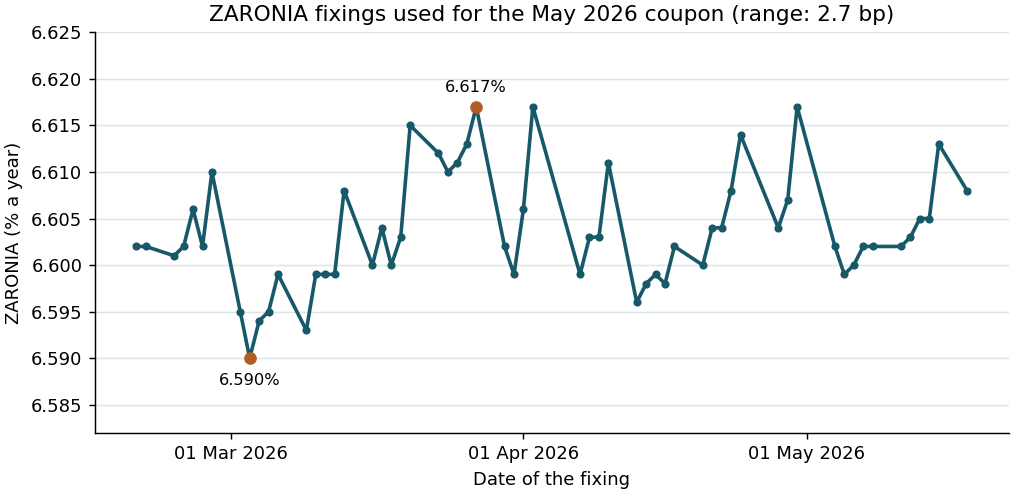

In [22]:
# The rates are stored as exact decimals, which matplotlib cannot plot, so we
# convert them to ordinary numbers for the chart.
fixing_rates = audit["daily_zaronia_pct"].astype(float)
range_bp = (fixing_rates.max() - fixing_rates.min()) * 100

fig, ax = plt.subplots(figsize=(7.8, 3.8), layout="constrained")
ax.plot(audit["observation_date"], fixing_rates, color="#175969", linewidth=2,
        marker="o", markersize=3.5)
# Mark the highest and lowest fixings and print their values, so that the size of
# the range can be read straight off the chart.
for position, offset in [(fixing_rates.idxmax(), 8), (fixing_rates.idxmin(), -15)]:
    point = (audit["observation_date"][position], fixing_rates[position])
    ax.scatter(*point, color="#b35d26", zorder=3)
    ax.annotate(f"{fixing_rates[position]:.3f}%", point, xytext=(0, offset),
                textcoords="offset points", ha="center", fontsize=9)
ax.set(title=f"ZARONIA fixings used for the {end:%B %Y} coupon (range: {range_bp:.1f} bp)",
       xlabel="Date of the fixing", ylabel="ZARONIA (% a year)",
       ylim=(fixing_rates.min() - 0.008, fixing_rates.max() + 0.008))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
ax.yaxis.set_major_formatter("{x:.3f}")
ax.grid(axis="y", color="#dbe4e7")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
save_and_show(fig, "zaronia_fixings_chart.png")

## 4b. Every coupon paid so far, checked against SENS

The same calculation now runs over every interest period whose fixings have been published, from the first, which started on 26 May 2025.

Each result is checked against the issuer's SENS notice in two ways.

* **The rate, at the notice's own precision.** The August 2025 notice prints four decimals and the May 2026 notice prints three (7.677, which could also be 7.6770 without its last zero), so the calculated coupon is rounded to however many decimals that notice shows before the two are compared. Comparing everything at three decimals would wrongly report a difference for a notice that prints, and agrees to, four.
* **The rand amount.** The total interest is worked out at the calculated rate on the nominal in issue, in the two rounding methods compared: rounded once on the whole issue, and rounded per R1 million calculation amount, which is the method condition 7.2(h) of the programme memorandum specifies. The cash check is the stronger of the two tests, because it pins down the rate, the day count and the nominal all at once.

Three periods have a repo-rate change inside their observation window, so ZARONIA steps by about 25 basis points part-way through (they show as a wide fixings range in the table). Those are harder tests of the lookback than the flat May 2026 period: picking up the step a day early or late would move the coupon in the fourth decimal and the cash by thousands of rand.

Two periods include a day with no fixing in the SARB's series, and Schedule 1, paragraph 2(a) supplies the rate. Every substitution is listed under the table.

**The published figures** come from `inputs/sens_notices.csv`, with a source for each row. The nominal for each payment comes from `inputs/nominal_history.csv`. A field stays empty until it has been read from the notice, and the table says so rather than guessing.

In [23]:
def coupon_for_period(start, end):
    """Compounded Daily ZARONIA and the coupon for one interest period, with any fallbacks used.

    A fixing date with no published rate takes the rate last published for an
    earlier business day, as Schedule 1, paragraph 2(a) requires (see fixing_for).
    """
    period = accrual_schedule(start, end)
    rates = [fixing_for(day) for day in period["observation_date"]]
    substitutions = [(day, SUBSTITUTED[day], series[SUBSTITUTED[day]])
                     for day in period["observation_date"] if day in SUBSTITUTED]
    benchmark = annualised_benchmark_pct(rates, period["weight_days"], (end - start).days)
    return benchmark, coupon_pct(benchmark), substitutions, max(rates) - min(rates)


def interest_cash(rate_pct, nominal, days):
    """Total interest in rand, under the two rounding methods compared.

    aggregate: interest on the whole nominal, rounded once to the cent.
    per_note: interest on one calculation amount, rounded to the cent (half up),
    then multiplied by the number of calculation amounts, as condition 7.2(h) of
    the programme memorandum reads.
    """
    per_rand = rate_pct / 100 * days / DAYS_IN_YEAR
    aggregate = round_half_up(nominal * per_rand, ".01")
    per_note = round_half_up(CALCULATION_AMOUNT * per_rand, ".01") * (nominal / CALCULATION_AMOUNT)
    return aggregate, per_note


rows, all_substitutions = [], []
for start, end in paid_periods:
    period_days = (end - start).days
    benchmark, calculated, substitutions, spread_of_rates = coupon_for_period(start, end)
    notice = PUBLISHED_NOTICES.get(end) or {}
    has_notice = bool(notice.get("rate") or notice.get("cash"))
    nominal = nominal_on(end)
    row = {
        "payment_date": end,
        "days": period_days,
        "benchmark_unrounded_pct": f"{benchmark:.8f}",
        "calculated_coupon_pct": f"{calculated}",
        "published_rate_pct": notice.get("rate") or ("not read" if has_notice else "notice not read"),
        "rate_check": "",
        "published_cash_rand": notice.get("cash") or "",
        "cash_diff_aggregate_rand": "",
        "cash_diff_per_note_rand": "",
        "nominal_rand": f"{nominal}" if has_notice else "",
        "fixings_range_bp": f"{spread_of_rates * 100:.1f}",
        "fallbacks_used": len(substitutions),
        "status": "",
    }
    # The rate, compared at however many decimals the notice prints.
    if notice.get("rate"):
        printed = D(notice["rate"])
        places = -printed.as_tuple().exponent
        ours = round_half_up(calculated, D(1).scaleb(-places))
        row["rate_check"] = (f"match at {places} dp" if ours == printed
                             else f"differs: ours {ours}, by {(ours - printed) * 100:+.2f} bp")
    # The rand amount at our calculated rate, both ways of rounding.
    if notice.get("cash"):
        aggregate, per_note = interest_cash(calculated, nominal, period_days)
        row["cash_diff_aggregate_rand"] = f"{aggregate - D(notice['cash']):+.2f}"
        row["cash_diff_per_note_rand"] = f"{per_note - D(notice['cash']):+.2f}"
    rate_ok = row["rate_check"].startswith("match")
    cash_ok = row["cash_diff_aggregate_rand"] != "" and D(row["cash_diff_aggregate_rand"]) == 0
    if not has_notice:
        row["status"] = "calculated only" + ("; fallback applied, unconfirmed" if substitutions else "")
    elif cash_ok:
        row["status"] = "rate and cash tie" if rate_ok else "cash ties"
    else:
        gap_pct = (D(row["cash_diff_aggregate_rand"]) / D(notice["cash"]) * 100).copy_abs()
        direction = "higher" if D(row["cash_diff_aggregate_rand"]) > 0 else "lower"
        row["status"] = (f"rate ties; our cash {gap_pct:.3f}% {direction}" if rate_ok
                         else f"rate and cash differ; our cash {gap_pct:.3f}% {direction}")
    rows.append(row)
    all_substitutions += [(end, *s) for s in substitutions]

every_coupon = pd.DataFrame(rows)
every_coupon.to_csv(OUTPUT_DIR / "every_coupon.csv", index=False)
display(every_coupon)

print("Fallback applied (Schedule 1, paragraph 2(a)); each is unconfirmed until the issuer's notice for that coupon is read:")
for payment, missing, earlier, rate in all_substitutions:
    print(f"  coupon of {payment}: {missing} uses the fixing for {earlier}, {rate}%")

rate_checked = [r for r in rows if r["rate_check"]]
cash_checked = [r for r in rows if r["cash_diff_aggregate_rand"]]
print(f"\nRates: {sum(r['rate_check'].startswith('match') for r in rate_checked)} of {len(rate_checked)} "
      "printed rates match at the notice's own precision.")
print("Cash at our calculated rate, rounded once on the whole issue: "
      f"{sum(D(r['cash_diff_aggregate_rand']) == 0 for r in cash_checked)} of {len(cash_checked)} tie to the cent.")
print("Cash rounded per calculation amount, as condition 7.2(h) reads: "
      f"{sum(D(r['cash_diff_per_note_rand']) == 0 for r in cash_checked)} of {len(cash_checked)} tie.")

,payment_date,days,benchmark_unrounded_pct,calculated_coupon_pct,published_rate_pct,rate_check,published_cash_rand,cash_diff_aggregate_rand,cash_diff_per_note_rand,nominal_rand,fixings_range_bp,fallbacks_used,status
0,2025-08-26,92,7.15130804,8.1713,8.1713,match at 4 dp,15570691.99,+0.00,-2.59,756000000,51.2,0,rate and cash tie
1,2025-11-26,92,6.91431212,7.9343,not read,,35917815.28,+0.00,-6.40,1796000000,3.5,0,cash ties
2,2026-02-26,92,6.66145486,7.6815,notice not read,,,,,,26.3,1,"calculated only; fallback applied, unconfirmed"
3,2026-05-26,89,6.65720308,7.6772,7.677,match at 3 dp,33619791.45,+875.86,+879.55,1796000000,2.7,0,rate ties; our cash 0.003% higher
4,2026-08-26,92,6.88579172,7.9058,notice not read,,,,,,26.3,2,"calculated only; fallback applied, unconfirmed"


Fallback applied (Schedule 1, paragraph 2(a)); each is unconfirmed until the issuer's notice for that coupon is read:
  coupon of 2026-02-26: 2026-01-29 uses the fixing for 2026-01-28, 6.6030%
  coupon of 2026-08-26: 2026-07-15 uses the fixing for 2026-07-14, 6.8520%
  coupon of 2026-08-26: 2026-07-16 uses the fixing for 2026-07-14, 6.8520%

Rates: 2 of 2 printed rates match at the notice's own precision.
Cash at our calculated rate, rounded once on the whole issue: 2 of 3 tie to the cent.
Cash rounded per calculation amount, as condition 7.2(h) reads: 0 of 3 tie.


### Would a wrong convention have been caught?

A match is only convincing if a plausible mistake would have failed. So this cell recomputes the three coupons whose cash we know, changing one convention at a time: a lookback of four or six business days instead of five, no lookback at all, an observation shift (weighting each fixing by its own calendar days rather than the accrual day's), a simple average instead of compounding, and the benchmark rounded to three decimals instead of four. Each variant is rounded and paid out exactly as before, and its cash is set against the notice.

On a flat quarter such as May 2026 the variants differ by a fraction of a basis point, which a three-decimal rate barely sees. The periods with a repo-rate step are where the test has teeth, and the rand amount is far more sensitive than the printed rate.

**What it shows.** Only the contract's convention ties both 2025 amounts to the cent. A lookback one business day out misses them by R10 000 to R29 000 (six days back reaches across the May 2025 rate cut, which is why August 2025 moves most), no lookback by R60 000 or more, and a simple average by six figures. The observation shift is the instructive case: in August 2025 it happens to give the same four-decimal coupon, so that period alone could not tell it apart, but November 2025 misses by about R900. No single period proves the convention; together they pin it down. Rounding the benchmark to three decimals is the one variant that ties May 2026, and it misses both 2025 amounts. So the published figures are consistent with four-decimal rounding in 2025 and three-decimal rounding in May 2026. That is consistent, not confirmed: section 5 takes it up.

In [24]:
def coupon_variant(start, end, lookback=LOOKBACK, observation_shift=False, simple_average=False,
                   benchmark_decimals=None):
    """The coupon for one period under a changed convention, or None if a fixing it needs is not loaded.

    With an observation shift, the weights follow the observation dates and the
    rate is annualised over the observation period's own days, which can differ
    from the interest period's.
    """
    day, rates, weights = start, [], []
    while day < end:
        next_day = move_business_days(day, 1)
        observed = move_business_days(day, -lookback)
        if not min(series) <= observed <= last_fixing_date:
            return None
        # Schedule 1, paragraph 2(a) for days with no fixing, as before, without
        # adding these hypothetical lookups to the log of substitutions.
        rates.append(fixing_for(observed, record=False))
        weights.append((move_business_days(observed, 1) - observed).days if observation_shift
                       else (next_day - day).days)
        day = next_day
    annualise_over = sum(weights) if observation_shift else (end - start).days
    if simple_average:
        benchmark = sum(r * w for r, w in zip(rates, weights)) / sum(weights)
    else:
        benchmark = annualised_benchmark_pct(rates, weights, annualise_over)
    if benchmark_decimals is not None:
        return round_half_up(benchmark, D(1).scaleb(-benchmark_decimals)) + MARGIN_PCT
    return coupon_pct(benchmark)


VARIANTS = {
    f"Contract: lookback {LOOKBACK}, no shift": {},
    f"Lookback {LOOKBACK - 1}": {"lookback": LOOKBACK - 1},
    f"Lookback {LOOKBACK + 1}": {"lookback": LOOKBACK + 1},
    "No lookback": {"lookback": 0},
    f"Observation shift, lookback {LOOKBACK}": {"observation_shift": True},
    f"Simple average, lookback {LOOKBACK}": {"simple_average": True},
    "Benchmark rounded to 3 decimals": {"benchmark_decimals": 3},
}
with_cash = [(s, e) for s, e in paid_periods if (PUBLISHED_NOTICES.get(e) or {}).get("cash")]
variant_rows = []
for name, options in VARIANTS.items():
    row = {"convention": name}
    for start, end in with_cash:
        notice = PUBLISHED_NOTICES[end]
        rate = coupon_variant(start, end, **options)
        if rate is None:
            row[f"{end} cash vs SENS (R)"] = "fixings not loaded"
            continue
        aggregate, _ = interest_cash(rate, nominal_on(end), (end - start).days)
        row[f"{end} coupon (%)"] = f"{rate}"
        row[f"{end} cash vs SENS (R)"] = f"{aggregate - D(notice['cash']):+,.2f}"
    variant_rows.append(row)

conventions = pd.DataFrame(variant_rows).set_index("convention")
conventions.to_csv(OUTPUT_DIR / "alternative_conventions.csv")
display(conventions)

# The contract's own convention must reproduce section 4b exactly.
contract = variant_rows[0]
for start, end in with_cash:
    assert contract[f"{end} coupon (%)"] == next(r["calculated_coupon_pct"] for r in rows if r["payment_date"] == end)
print("The contract row reproduces section 4b.")
for start, end in with_cash:
    column = f"{end} cash vs SENS (R)"
    tied = [r["convention"] for r in variant_rows if r.get(column) == "+0.00"]
    print(f"  {end}: conventions whose cash ties to the cent: {', '.join(tied) or 'none'}")

,2025-08-26 coupon (%),2025-08-26 cash vs SENS (R),2025-11-26 coupon (%),2025-11-26 cash vs SENS (R),2026-05-26 coupon (%),2026-05-26 cash vs SENS (R)
convention,,,,,,
"Contract: lookback 5, no shift",8.1713,+0.00,7.9343,+0.00,7.6772,+875.86
Lookback 4,8.1646,"-12,767.08",7.9315,"-12,675.33",7.6762,"-3,503.43"
Lookback 6,8.1867,"+29,345.23",7.9320,"-10,411.88",7.6754,"-7,006.86"
No lookback,8.1329,"-73,172.52",7.9206,"-62,018.59",7.6794,"+10,510.29"
"Observation shift, lookback 5",8.1713,+0.00,7.9345,+905.38,7.6781,"+4,817.22"
"Simple average, lookback 5",8.1089,"-118,905.34",7.8760,"-263,918.51",7.6250,"-227,722.96"
Benchmark rounded to 3 decimals,8.171,-571.66,7.934,"-1,358.07",7.677,+0.00


The contract row reproduces section 4b.
  2025-08-26: conventions whose cash ties to the cent: Contract: lookback 5, no shift, Observation shift, lookback 5
  2025-11-26: conventions whose cash ties to the cent: Contract: lookback 5, no shift
  2026-05-26: conventions whose cash ties to the cent: Benchmark rounded to 3 decimals


### ZARONIA over the life of the note so far

The chart shows each daily fixing, the repo rate, and the calculated coupon for each period. ZARONIA tracks a little below the repo rate and steps when the MPC moves; the cell prints the median gap. The repo rate decisions come from `inputs/repo_rate_changes.csv`, one row per MPC statement, with the date each took effect. The thin vertical lines mark the days with no fixing in the series.

ZARONIA sat a median 14.7 bp below the repo rate over this window (range 11.8 to 21.3 bp).


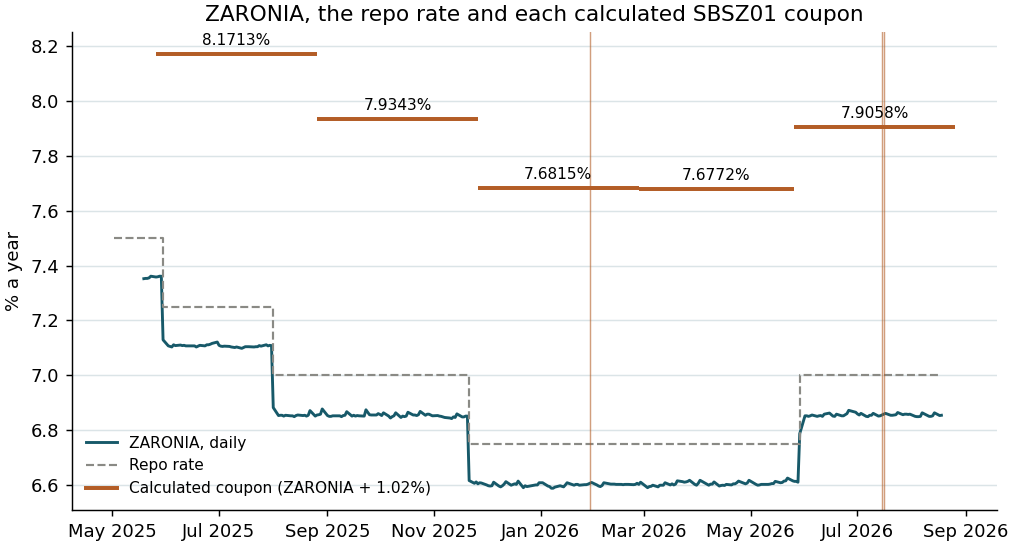

In [25]:
# The repo rate comes from inputs/repo_rate_changes.csv, one row per MPC decision,
# each with the date it took effect and the SARB statement it comes from.
def repo_on(day):
    """The repo rate in force on a given day."""
    return [rate for changed, rate in REPO_CHANGES if changed <= day][-1]


gaps_bp = sorted((repo_on(d) - float(fixings[d])) * 100 for d in fixings)
median_gap_bp = gaps_bp[len(gaps_bp) // 2]
print(f"ZARONIA sat a median {median_gap_bp:.1f} bp below the repo rate over this window "
      f"(range {gaps_bp[0]:.1f} to {gaps_bp[-1]:.1f} bp).")

days_sorted = sorted(fixings)
fig, ax = plt.subplots(figsize=(7.8, 4.2), layout="constrained")
ax.plot(days_sorted, [float(fixings[d]) for d in days_sorted], color="#175969", linewidth=1.6, label="ZARONIA, daily")

# The repo rate as a step line, carried to the end of the window.
in_window = [(d, r) for d, r in REPO_CHANGES if d <= days_sorted[-1]]
repo_x = [d for d, _ in in_window] + [days_sorted[-1]]
repo_y = [r for _, r in in_window] + [in_window[-1][1]]
ax.step(repo_x, repo_y, where="post", color="#8a8a85", linewidth=1.2, linestyle="--", label="Repo rate")

# Each coupon as a flat bar over its interest period, at its contractual rate.
for row, (start, end) in zip(rows, paid_periods):
    level = float(row["calculated_coupon_pct"])
    ax.hlines(level, start, end, color="#b35d26", linewidth=2.2)
    ax.annotate(f"{row['calculated_coupon_pct']}%", ((start + (end - start) / 2), level), xytext=(0, 5),
                textcoords="offset points", ha="center", fontsize=8.5)
ax.plot([], [], color="#b35d26", linewidth=2.2, label=f"Calculated coupon (ZARONIA + {MARGIN_PCT}%)")

# Days with no published fixing, where the fallback was used.
for missing in sorted(SUBSTITUTED):
    ax.axvline(missing, color="#b35d26", linewidth=0.8, alpha=0.6)
ax.set(title=f"ZARONIA, the repo rate and each calculated {TERMS_FILE['note']} coupon", ylabel="% a year")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(axis="y", color="#dbe4e7")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
save_and_show(fig, "zaronia_history.png")

## 5. Compare the reported rand payment for May 2026

The SENS notice also gives the total interest paid, R33 619 791.45, and that gives a second check on the rate. The notice does not state the nominal, so we take it from `inputs/nominal_history.csv`: R1.796 billion, from the issuer's tap announcement of 17 September 2025. Section 4b shows that nominal reproducing the November 2025 payment to the cent, and the May amount itself ties to the cent on it at the printed rate, so it is well supported.

There are two ways to round. One is to work out the interest on the whole R1.796 billion and round once at the end. The other is what condition 7.2(h) of the programme memorandum dated 19 December 2024 (printed page 49) says: work out the interest on one R1 million calculation amount, round that to the cent, half up, and multiply by the number of notes. The pricing supplement disapplies only condition 7.2(e), so 7.2(h) still governs. We try both, at the published 7.677% and at our own four-decimal rate.

Only one of the four combinations reproduces the notice exactly: the published 7.677%, rounded once on the full nominal. Our rate of 7.6772% gives R875.86 more than the notice when rounded once on the issue, and R879.55 more across the issue when rounded per R1 million. Even at 7.677%, rounding per R1 million gives 49 cents less across the issue than the notice.

Read with section 4b, the picture is this.

* **The rate in May.** In August and November 2025 the amounts tie at the four-decimal rate. In May 2026 the amount ties at the rate as printed, 7.677%, which is what rounding the benchmark to three decimals gives; our four-decimal 7.6772% would pay R875.86 more across the issue, about 49 cents per R1 million note. That is consistent with a change in rounding precision, but the notice cannot confirm it, and the calculation agent's worksheet would.
* **Cash rounding.** On these nominals all three amounts reproduce when the interest is rounded once on the whole issue. The difference from rounding per R1 million, as condition 7.2(h) reads, is R0.49 to R6.40 across the issue: immaterial, and noted only for completeness.

Neither point is material. Both are recorded as they stand, without changing any input to make the figures agree.

In [26]:
# The walkthrough payment's rand amount, from inputs/sens_notices.csv, and the
# nominal in issue on that date, from inputs/nominal_history.csv.
reported_cash = D(walkthrough_notice["cash"]) if walkthrough_notice.get("cash") else None
walkthrough_nominal = nominal_on(WALKTHROUGH_PAYMENT)

cash_comparison = []
if reported_cash is None or PUBLISHED_PCT is None:
    print(f"The notice for {WALKTHROUGH_PAYMENT} has no rate or amount in inputs/sens_notices.csv, so there is no cash to compare.")
else:
    for label, rate in [("Published display rate", PUBLISHED_PCT), ("Calculated contract rate", contractual)]:
        # Interest on one rand for the period: the annual rate for the period's days out of 365.
        cash_per_rand = rate / 100 * days / DAYS_IN_YEAR
        # First method: work out the interest on the whole issue and round once.
        aggregate = round_half_up(walkthrough_nominal * cash_per_rand, ".01")
        # Second method: round the interest on one calculation amount to the cent,
        # then multiply by the number of calculation amounts.
        per_note = round_half_up(CALCULATION_AMOUNT * cash_per_rand, ".01")
        rounded_per_note_total = per_note * (walkthrough_nominal / CALCULATION_AMOUNT)
        cash_comparison.extend([
            (label, f"{rate}%", "Round aggregate", aggregate, aggregate - reported_cash),
            (label, f"{rate}%", "Round each R1m first", rounded_per_note_total,
             rounded_per_note_total - reported_cash),
        ])
    print(f"Nominal in issue on {WALKTHROUGH_PAYMENT}: R{walkthrough_nominal:,.0f}; published interest R{reported_cash:,.2f}")
    display(pd.DataFrame(cash_comparison, columns=[
        "Rate basis", "Coupon", "Cash rounding", "Total (R)", "Less published amount (R)"
    ]))

Nominal in issue on 2026-05-26: R1,796,000,000; published interest R33,619,791.45


,Rate basis,Coupon,Cash rounding,Total (R),Less published amount (R)
0,Published display rate,7.677%,Round aggregate,33619791.45,0.00
1,Published display rate,7.677%,Round each R1m first,33619790.96,-0.49
2,Calculated contract rate,7.6772%,Round aggregate,33620667.31,875.86
3,Calculated contract rate,7.6772%,Round each R1m first,33620671.00,879.55


## 6. Project the remaining cash flows

For the second question we move to the moment just after the May coupon has been paid. Nothing has accrued yet at that point, so there is no accrued interest to deal with and the price we calculate is a clean price.

Eight quarterly payments remain, and the last of them also repays the R100 of principal on 26 May 2028. Nobody knows what those coupons will be, because they depend on ZARONIA fixings that have not happened yet, so we have to assume something. We keep the assumption as simple as we can: every future fixing is taken to equal the most recent one available, the fixing for 25 May 2026. In market terms this is a flat forward curve. It is easy to explain and easy to criticise, and it contains no view on what the Reserve Bank will do next.

There is one refinement. The first five fixings of the next coupon period are not forecasts at all. Because of the lookback they had already been published by 26 May, so we use the actual numbers for those.

Each projected coupon is then worked out with the same compounding function that we used for the May coupon.

In [27]:
# The valuation date is the walkthrough payment date, just after that coupon.
# ZARONIA for a day is published the next morning, so the newest fixing available
# on the valuation date is the one for the previous business day.
VALUATION_DATE = WALKTHROUGH_PAYMENT
last_published_date = move_business_days(VALUATION_DATE, -1)
# The flat forward assumption: every fixing not yet published on the valuation date
# is set equal to the last one that was.
FORWARD_PCT = fixing_for(last_published_date)
# The base case discounts at the same margin that the note pays.
BASE_DISCOUNT_MARGIN_BP = int(MARGIN_PCT * 100) if MARGIN_PCT * 100 % 1 == 0 else float(MARGIN_PCT * 100)
# All cash flows and prices are expressed per R100 of nominal.
NOMINAL = 100

# The remaining interest periods, straight from the schedule built in section 2.
remaining = [(s, e, scheduled) for (s, e), scheduled in zip(all_periods, scheduled_dates) if s >= VALUATION_DATE]
payment_dates = [e for _, e, _ in remaining]

cash_flow_rows = []
for previous, payment, scheduled in remaining:
    period = accrual_schedule(previous, payment)
    period_days = (payment - previous).days
    # Use the real fixing where one had been published, and the flat forward otherwise.
    projected_rates = [fixing_for(day) if day <= last_published_date else FORWARD_PCT
                       for day in period["observation_date"]]
    # Compound the projected rates in exactly the same way as for the coupon itself.
    benchmark_pct = round_half_up(annualised_benchmark_pct(
        projected_rates, period["weight_days"], period_days), BENCHMARK_QUANTUM)
    projected_coupon_pct = benchmark_pct + MARGIN_PCT
    year_fraction = period_days / DAYS_IN_YEAR
    # The coupon in rand per R100: nominal, times the annual rate, times the part
    # of a year the period lasts. From here on we use ordinary floating-point
    # numbers, because the pricing involves no contractual rounding.
    coupon_cash = NOMINAL * float(projected_coupon_pct) / 100 * year_fraction
    # The principal is repaid together with the final coupon.
    redemption = NOMINAL if scheduled == MATURITY else 0
    cash_flow_rows.append((previous, scheduled, payment, period_days, year_fraction,
                           float(benchmark_pct), float(projected_coupon_pct), coupon_cash, redemption))

cash_flows = pd.DataFrame(cash_flow_rows, columns=[
    "accrual_start", "scheduled_date", "payment_date", "days", "year_fraction",
    "benchmark_pct", "coupon_pct", "coupon_per_R100", "redemption_per_R100",
])
cash_flows["total_per_R100"] = cash_flows["coupon_per_R100"] + cash_flows["redemption_per_R100"]

print(f"Valued on {VALUATION_DATE} | {len(cash_flows)} remaining payments | flat overnight forward {FORWARD_PCT}%")
display(cash_flows.round(6))

Valued on 2026-05-26 | 8 remaining payments | flat overnight forward 6.6150%


,accrual_start,scheduled_date,payment_date,days,year_fraction,benchmark_pct,coupon_pct,coupon_per_R100,redemption_per_R100,total_per_R100
0,2026-05-26,2026-08-26,2026-08-26,92,0.252055,6.6695,7.6895,1.938175,0,1.938175
1,2026-08-26,2026-11-26,2026-11-26,92,0.252055,6.6693,7.6893,1.938125,0,1.938125
2,2026-11-26,2027-02-26,2027-02-26,92,0.252055,6.6692,7.6892,1.938100,0,1.938100
3,2027-02-26,2027-05-26,2027-05-26,89,0.243836,6.6673,7.6873,1.874438,0,1.874438
4,2027-05-26,2027-08-26,2027-08-26,92,0.252055,6.6693,7.6893,1.938125,0,1.938125
5,2027-08-26,2027-11-26,2027-11-26,92,0.252055,6.6693,7.6893,1.938125,0,1.938125
6,2027-11-26,2028-02-26,2028-02-28,94,0.257534,6.6705,7.6905,1.980567,0,1.980567
7,2028-02-28,2028-05-26,2028-05-26,88,0.241096,6.6668,7.6868,1.853256,100,101.853256


## 7. Run the discount margin scenarios, and solve the other way

**Scenario valuation on 26 May 2026, just after the coupon, per R100 nominal. The base discount margin of 102 bp is an assumption, and the same projected cash flows are used in all three scenarios.**

The contractual margin, 102 bp, is written into the pricing supplement and sets the cash the note pays. The discount margin is the spread over ZARONIA that investors want today, and it sets the price. When the two are equal the note is worth exactly R100, whatever the shape of the forward curve, so the base price says nothing about the market. Widening the discount margin to 127 and 152 bp shows what the price would be if investors wanted more.

The cell also solves the problem the other way. Given a price, `implied_discount_margin` finds the spread that produces it. That is how the model would be used with a real price: a trade, a quote, a JSE mark-to-market or an auction result. The round trip, from each scenario price back to its margin, is checked.

Discounting each period at its projected compounded ZARONIA is what a ZARONIA swap curve gives when it is flat, so the real simplification here is the flat curve. A live valuation would take forwards and discount factors from the swap curve on the day.

In [28]:
def discount_factors(discount_margin_bp):
    """The discount factor for each payment date at a given discount margin.

    Each period is discounted at its own projected ZARONIA rate plus the discount
    margin, as simple interest over the period. Multiplying those period by period
    and taking the reciprocal gives the factor that brings a payment on that date
    back to the valuation date.
    """
    discount_rate = cash_flows["benchmark_pct"] / 100 + discount_margin_bp / 10_000
    return (1 + discount_rate * cash_flows["year_fraction"]).cumprod().rdiv(1)


def price(discount_margin_bp):
    """The price per R100: each remaining cash flow times its discount factor, added up."""
    return (cash_flows["total_per_R100"] * discount_factors(discount_margin_bp)).sum()


# Keep the base-case discount factors and present values in the table for reference.
cash_flows["base_discount_factor"] = discount_factors(BASE_DISCOUNT_MARGIN_BP)
cash_flows["base_PV_per_R100"] = cash_flows["total_per_R100"] * cash_flows["base_discount_factor"]
# Checks on the schedule: payments that end at maturity, periods that join
# up without gaps, the principal repaid exactly once, and discount factors that
# get smaller with every payment.
assert cash_flows["scheduled_date"].iloc[-1] == MATURITY
assert cash_flows["days"].sum() == (payment_dates[-1] - VALUATION_DATE).days
assert cash_flows["redemption_per_R100"].sum() == NOMINAL
assert cash_flows["base_discount_factor"].diff().dropna().lt(0).all()
cash_flows.to_csv(OUTPUT_DIR / "projected_cash_flows.csv", index=False)


# The scenarios: the base case, then the discount margin wider by each step in
# SCENARIO_WIDENINGS_BP (set in section 1).
scenario = pd.DataFrame({"widening_bp": SCENARIO_WIDENINGS_BP})
scenario["discount_margin_bp"] = BASE_DISCOUNT_MARGIN_BP + scenario["widening_bp"]
scenario["price_per_R100"] = scenario["discount_margin_bp"].map(price)
scenario["change_per_R100"] = scenario["price_per_R100"] - price(BASE_DISCOUNT_MARGIN_BP)
# Checks on the prices: each wider margin gives a lower price, the present values
# add up to the base price, and the base price is par.
assert scenario["price_per_R100"].diff().dropna().lt(0).all()
assert abs(cash_flows["base_PV_per_R100"].sum() - scenario["price_per_R100"].iloc[0]) < 1e-10
assert abs(price(BASE_DISCOUNT_MARGIN_BP) - NOMINAL) < 1e-10
# The spread PV01 is the price change for a 1 bp move in the discount margin. We
# measure it by moving the margin 1 bp each way and halving the difference.
spread_pv01 = (price(BASE_DISCOUNT_MARGIN_BP - 1) - price(BASE_DISCOUNT_MARGIN_BP + 1)) / 2
print(f"Flat overnight forward {FORWARD_PCT}% | local spread PV01 R{spread_pv01:.5f} per R100.")
print("Cash-flow, base par and price monotonicity checks passed.")
scenario.to_csv(OUTPUT_DIR / "pricing_scenarios.csv", index=False)
display(scenario.round(4))


def implied_discount_margin(target_price, low_bp=-500.0, high_bp=1500.0):
    """The discount margin, in bp, at which the model gives `target_price`.

    Price falls steadily as the margin rises, so halving the interval until it is
    a ten-thousandth of a basis point wide always finds the answer.
    """
    if not price(high_bp) <= target_price <= price(low_bp):
        raise ValueError("Target price is outside the range the solver searches.")
    while high_bp - low_bp > 1e-4:
        middle = (low_bp + high_bp) / 2
        low_bp, high_bp = (middle, high_bp) if price(middle) > target_price else (low_bp, middle)
    return (low_bp + high_bp) / 2


# Round trip: each scenario price should give back the margin that produced it.
for row in scenario.itertuples(index=False):
    recovered = implied_discount_margin(row.price_per_R100)
    assert abs(recovered - row.discount_margin_bp) < 1e-3
print("Implied discount margin solver: each scenario price gives back its margin to within 0.001 bp.")
print(f"For example, a price of R99.50 implies a discount margin of {implied_discount_margin(99.50):.2f} bp.")

Flat overnight forward 6.6150% | local spread PV01 R0.01840 per R100.
Cash-flow, base par and price monotonicity checks passed.


,widening_bp,discount_margin_bp,price_per_R100,change_per_R100
0,0,102,100.0000,0.0000
1,25,127,99.5413,-0.4587
2,50,152,99.0850,-0.9150


Implied discount margin solver: each scenario price gives back its margin to within 0.001 bp.
For example, a price of R99.50 implies a discount margin of 129.26 bp.


## 8. Plot the spread sensitivity

The chart runs the same model across discount margins from 25 basis points below the base case to 75 above it and marks the three scenarios from the table above. The line slopes downwards all the way: the wider the margin investors ask for, the less they are prepared to pay. It is also very nearly straight over this range, which tells us that the PV01 from the previous section is a good guide to moves of this size.

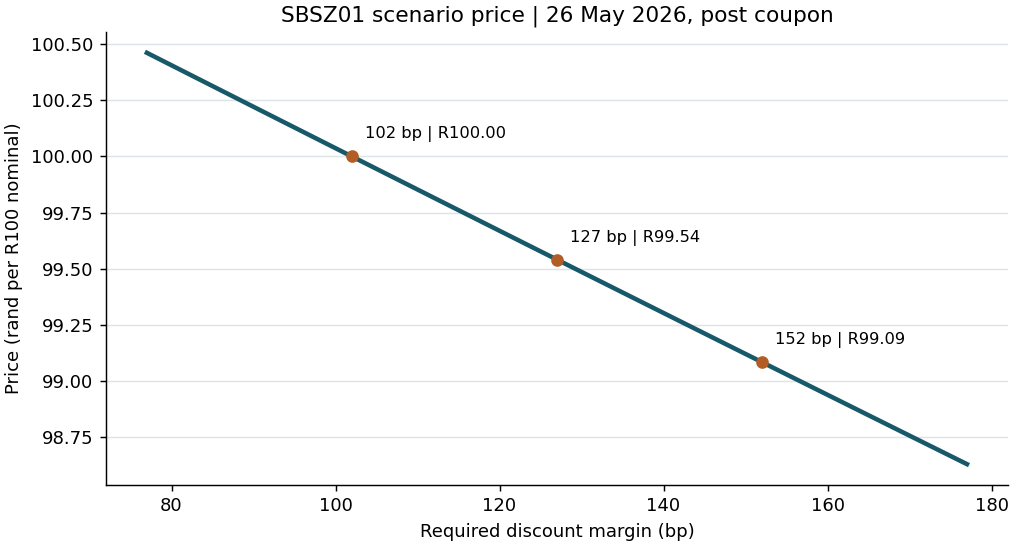

In [29]:
# Price the note across a range of discount margins around the base case to draw the line.
low = int(BASE_DISCOUNT_MARGIN_BP) - 25
margin_grid = range(low, low + 101)
fig, ax = plt.subplots(figsize=(7.8, 4.2), layout="constrained")
ax.plot(margin_grid, [price(margin) for margin in margin_grid],
        color="#175969", linewidth=2.5)
# Mark the three scenarios from the table and label each with its margin and price.
ax.scatter(scenario["discount_margin_bp"], scenario["price_per_R100"],
           color="#b35d26", zorder=3)
for row in scenario.itertuples(index=False):
    ax.annotate(f"{row.discount_margin_bp:g} bp | R{row.price_per_R100:.2f}",
                (row.discount_margin_bp, row.price_per_R100),
                xytext=(7, 10), textcoords="offset points", fontsize=9)
ax.set(title=f"{TERMS_FILE['note']} scenario price | {VALUATION_DATE:%d %B %Y}, post coupon",
       xlabel="Required discount margin (bp)", ylabel="Price (rand per R100 nominal)")
ax.grid(axis="y", color="#dbe4e7")
ax.spines[["top", "right"]].set_visible(False)
save_and_show(fig, "price_vs_discount_margin.png")

## Regression check: do the results still hold?

A notebook that runs to the end has only shown that no cell crashed. This cell checks the answers. On the saved SARB reply, the headline results are known, so it asserts them: the five calculated coupons, the two cash amounts that tie to the cent, the May difference, the observation shift's miss in November, the three-decimal variant's tie in May, the three fallback days and the scenario prices. The GitHub workflow runs the notebook on every change, so a change that moves any of these turns the check red instead of quietly producing a different number.

With `REFRESH_FROM_SARB` ticked, the live data may differ, so the cell reports any difference instead of stopping.

In [30]:
# The results the summary reports, on the saved SARB reply (data as of 13 November 2026).
# Like the known-answer tests, these values are written out on purpose: the check
# is that the code still reproduces them.
EXPECTED = {
    "coupons": {"2025-08-26": "8.1713", "2025-11-26": "7.9343", "2026-02-26": "7.6815",
                "2026-05-26": "7.6772", "2026-08-26": "7.9058"},
    "cash vs SENS, rounded once on the issue": {"2025-08-26": "+0.00", "2025-11-26": "+0.00", "2026-05-26": "+875.86"},
    "observation shift, Nov 2025 cash vs SENS": "+905.38",
    "benchmark rounded to 3 decimals, May 2026 cash vs SENS": "+0.00",
    "fallback days": ["2026-01-29", "2026-07-15", "2026-07-16"],
    "scenario prices per R100": ["100.0000", "99.5413", "99.0850"],
}
found = {
    "coupons": {str(r["payment_date"]): r["calculated_coupon_pct"] for r in rows},
    "cash vs SENS, rounded once on the issue": {str(r["payment_date"]): r["cash_diff_aggregate_rand"]
                                                for r in rows if r["cash_diff_aggregate_rand"]},
    "observation shift, Nov 2025 cash vs SENS":
        conventions.loc[f"Observation shift, lookback {LOOKBACK}", "2025-11-26 cash vs SENS (R)"],
    "benchmark rounded to 3 decimals, May 2026 cash vs SENS":
        conventions.loc["Benchmark rounded to 3 decimals", "2026-05-26 cash vs SENS (R)"],
    "fallback days": [str(d) for d in sorted(SUBSTITUTED)],
    "scenario prices per R100": [f"{p:.4f}" for p in scenario["price_per_R100"]],
}
differences = {name: (EXPECTED[name], found[name]) for name in EXPECTED if EXPECTED[name] != found[name]}
if REFRESH_FROM_SARB:
    print("Live data: results differ from the summary in:" if differences else
          "Live data: every headline result matches the summary.", differences or "")
else:
    assert not differences, f"Results no longer match the summary: {differences}"
    print("Regression check passed: every headline result matches the summary.")

Regression check passed: every headline result matches the summary.


## 9. Export the results

The last cell gathers everything into one ZIP file: the fixings used and where they came from, the row-by-row audit of the walkthrough coupon, the table of every coupon, the rand comparison, the projected cash flows, the pricing scenarios and all four charts.

The summary file also records the SHA-256 of every input file, so a result can always be traced to the exact inputs that produced it.

In [31]:
provenance.update({
    "series": SARB_SERIES,
    "required_reference_dates": [str(all_required[0]), str(all_required[-1])],
    "no_fixing_published_on": [str(d) for d in sorted(SUBSTITUTED)],
    "fallback_substitutions": {str(d): str(e) for d, e in sorted(SUBSTITUTED.items())},
    "inputs": {name: sha256((PROJECT / name).read_bytes()).hexdigest() for name in INPUT_FILES},
    "pricing_supplement_url": TERMS_FILE["source_url"],
    "walkthrough_payment_date": str(WALKTHROUGH_PAYMENT),
    "walkthrough_coupon": comparison,
    "may_2026_coupon": comparison,   # the name the PDF and deck builders read
    "every_coupon": rows,
    "published_notices": {str(k): v for k, v in PUBLISHED_NOTICES.items()},
    "repo_changes": [(str(d), r) for d, r in REPO_CHANGES],
    "median_repo_minus_zaronia_bp": round(median_gap_bp, 1),
    "flat_forward_pct": str(FORWARD_PCT),
    "spread_pv01_rand_per_R100": round(spread_pv01, 6),
})
(OUTPUT_DIR / "sources_and_summary.json").write_text(json.dumps(provenance, indent=2, default=str), encoding="utf-8")
pd.DataFrame(cash_comparison, columns=[
    "rate_basis", "coupon", "cash_rounding", "total_rand", "difference_vs_sens_rand"
]).to_csv(OUTPUT_DIR / "conditional_cash_reconciliation.csv", index=False)

# Zip every file the notebook wrote, so the results come down in one go.
with ZipFile(RESULTS_ZIP, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(OUTPUT_DIR.iterdir()):
        archive.write(path, arcname=path.name)
print(f"Done. Download {RESULTS_ZIP.name} from Colab's Files sidebar.")

Done. Download SBSZ01_results.zip from Colab's Files sidebar.
